# Ejercicio k-Nearest Neighbor

## App Reviews
En este ejercicio vas a trabajar con una base de datos de reviews de una aplicación. Entre los datos podemos encontrar el texto de la review, las estrellas, así como el sentimiento del comentario (si es algo bueno o malo).

El objetivo es montar un algoritmo de clasificación que prediga el rating, en función del sentimiento del comentario y la cantidad de palabras empleadas en el mismo. Para ello tendrás que utilizar un algoritmo de tipo KNN.

## Importamos las librerías que vamos a utilizar

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Leemos nuestro archivo de entrada `reviews_sentiment`

Para facilitar el ejercicio, las columnas que utilizaremos serán: wordcount con la cantidad de palabras utilizadas y sentimentValue con un valor entre -4 y 4 que indica si el comentario fue valorado como positivo o negativo

Nuestras etiquetas, serán las estrellas que dieron los usuarios a la app, que son valores discretos del 1 al 5

In [10]:
df_reviews= pd.read_csv("data/reviews_sentiment.csv", sep=';')
df_reviews

,Review Title,Review Text,wordcount,titleSentiment,textSentiment,Star Rating,sentimentValue
0,Sin conexión,Hola desde hace algo más de un mes me pone sin...,23,negative,negative,1,-0.486389
1,faltan cosas,Han mejorado la apariencia pero no,20,negative,negative,1,-0.586187
2,Es muy buena lo recomiendo,Andres e puto amoooo,4,NaN,negative,1,-0.602240
3,Version antigua,Me gustana mas la version anterior esta es mas...,17,NaN,negative,1,-0.616271
4,Esta bien,Sin ser la biblia.... Esta bien,6,negative,negative,1,-0.651784
...,...,...,...,...,...,...,...
252,Muy buena aplicacion,Muy buena genial,3,positive,positive,5,2.814818
253,Buena,Genial,1,positive,positive,5,2.924393
254,Wuau,Genial,1,positive,positive,5,2.924393
255,Muy buena,Genial,1,positive,positive,5,2.924393


In [11]:
df_reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Review Title    257 non-null    str    
 1   Review Text     257 non-null    str    
 2   wordcount       257 non-null    int64  
 3   titleSentiment  231 non-null    str    
 4   textSentiment   257 non-null    str    
 5   Star Rating     257 non-null    int64  
 6   sentimentValue  257 non-null    float64
dtypes: float64(1), int64(2), str(4)
memory usage: 29.3 KB


In [12]:
print(df_reviews.isna().sum())
print("Filas antes:", len(df_reviews))

# Eliminar filas que contengan cualquier valor nulo
df_reviews = df_reviews.dropna(axis=0, how="any").reset_index(drop=True)

print("Filas después:", len(df_reviews))
print(df_reviews.isna().sum())

Review Title       0
Review Text        0
wordcount          0
titleSentiment    26
textSentiment      0
Star Rating        0
sentimentValue     0
dtype: int64
Filas antes: 257
Filas después: 231
Review Title      0
Review Text       0
wordcount         0
titleSentiment    0
textSentiment     0
Star Rating       0
sentimentValue    0
dtype: int64


## Rápidas visualizaciones y análisis
Al menos realiza un análisis univariante y representa la distribución del rating. Realiza otras visualizaciones para ver la relación de tus datos.

In [13]:
df_reviews.describe()

,wordcount,Star Rating,sentimentValue
count,231.000000,231.000000,231.000000
mean,11.709957,3.398268,0.370385
std,12.976495,1.416302,0.909308
min,1.000000,1.000000,-2.276469
25%,3.000000,3.000000,-0.107949
50%,7.000000,3.000000,0.246869
75%,16.000000,5.000000,0.791747
max,103.000000,5.000000,3.264579


--- Resumen variables numéricas ---
        wordcount  Star Rating  sentimentValue
count  231.000000   231.000000      231.000000
mean    11.709957     3.398268        0.370385
std     12.976495     1.416302        0.909308
min      1.000000     1.000000       -2.276469
25%      3.000000     3.000000       -0.107949
50%      7.000000     3.000000        0.246869
75%     16.000000     5.000000        0.791747
max    103.000000     5.000000        3.264579

--- Frecuencias variables categóricas ---

Columna: titleSentiment
titleSentiment
positive    195
negative     36
Name: count, dtype: int64
titleSentiment
positive    84.42%
negative    15.58%
Name: proportion, dtype: str

Columna: textSentiment
textSentiment
positive    189
negative     42
Name: count, dtype: int64
textSentiment
positive    81.82%
negative    18.18%
Name: proportion, dtype: str

Columna: Star Rating
Star Rating
5    78
3    69
1    34
4    27
2    23
Name: count, dtype: int64
Star Rating
5    33.77%
3    29.87%
1    

C:\Users\haize\AppData\Local\Temp\ipykernel_30156\3187807865.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


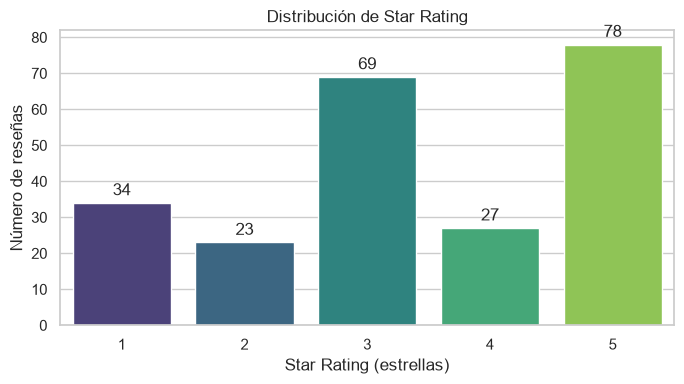

C:\Users\haize\AppData\Local\Temp\ipykernel_30156\3187807865.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\haize\AppData\Local\Temp\ipykernel_30156\3187807865.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


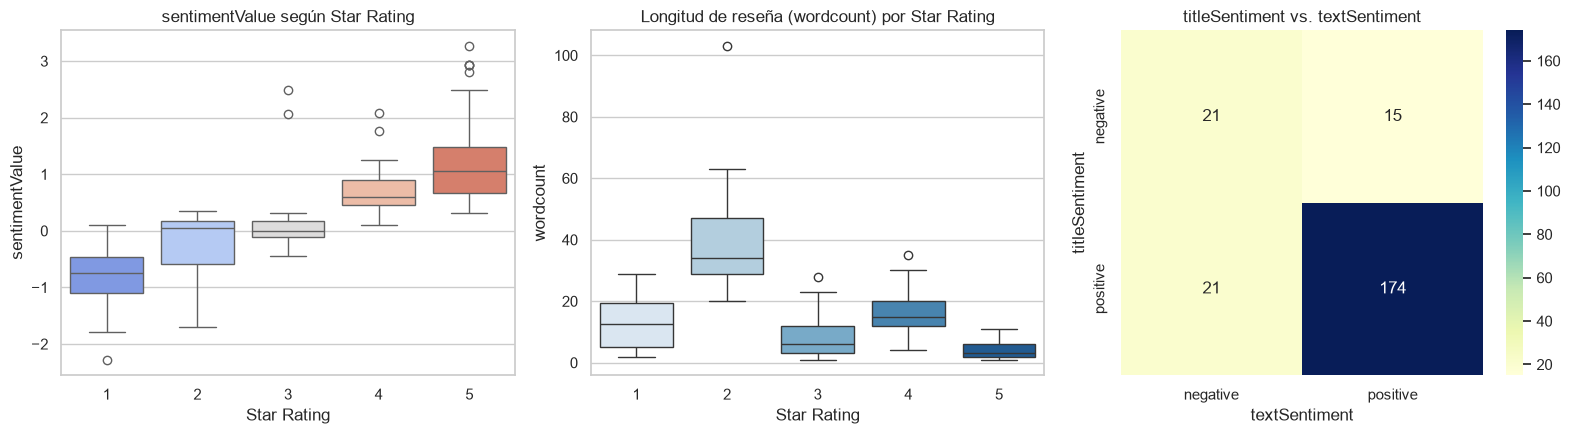

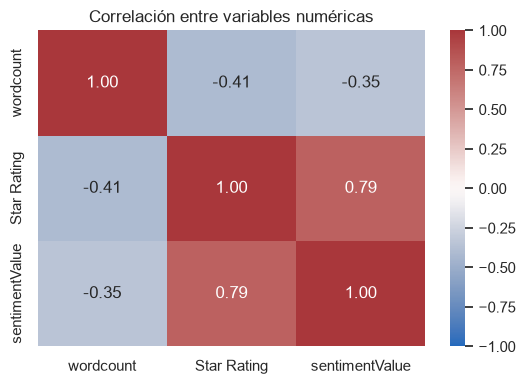

In [14]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

# 0. Opcional: trabajar sobre el DataFrame sin filas nulas
df_eda = df_reviews.dropna(axis=0, how="any").reset_index(drop=True)

# ---------------------------------------------------------
# 1. ANÁLISIS UNIVARIANTE
# ---------------------------------------------------------
print("--- Resumen variables numéricas ---")
print(df_eda[["wordcount", "Star Rating", "sentimentValue"]].describe())

print("\n--- Frecuencias variables categóricas ---")
for col in ["titleSentiment", "textSentiment", "Star Rating"]:
    print(f"\nColumna: {col}")
    print(df_eda[col].value_counts(dropna=False))
    print(
        (df_eda[col].value_counts(normalize=True) * 100).round(2).astype(str)
        + "%"
    )

# ---------------------------------------------------------
# 2. DISTRIBUCIÓN DEL STAR RATING
# ---------------------------------------------------------
plt.figure(figsize=(7, 4))
ax = sns.countplot(
    data=df_eda,
    x="Star Rating",
    order=sorted(df_eda["Star Rating"].dropna().unique()),
    palette="viridis",
)
plt.title("Distribución de Star Rating")
plt.xlabel("Star Rating (estrellas)")
plt.ylabel("Número de reseñas")

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. RELACIONES ENTRE VARIABLES
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# A) sentimentValue según Star Rating
sns.boxplot(
    data=df_eda,
    x="Star Rating",
    y="sentimentValue",
    ax=axes[0],
    palette="coolwarm",
)
axes[0].set_title("sentimentValue según Star Rating")
axes[0].set_xlabel("Star Rating")
axes[0].set_ylabel("sentimentValue")

# B) wordcount según Star Rating
sns.boxplot(
    data=df_eda, x="Star Rating", y="wordcount", ax=axes[1], palette="Blues"
)
axes[1].set_title("Longitud de reseña (wordcount) por Star Rating")
axes[1].set_xlabel("Star Rating")
axes[1].set_ylabel("wordcount")

# C) Relación entre sentimiento del texto y del título
ct = pd.crosstab(df_eda["titleSentiment"], df_eda["textSentiment"])
sns.heatmap(ct, annot=True, fmt="d", cmap="YlGnBu", ax=axes[2])
axes[2].set_title("titleSentiment vs. textSentiment")
axes[2].set_xlabel("textSentiment")
axes[2].set_ylabel("titleSentiment")

plt.tight_layout()
plt.show()

# D) Matriz de correlación entre variables numéricas
plt.figure(figsize=(5.5, 4))
corr = df_eda[["wordcount", "Star Rating", "sentimentValue"]].corr(
    numeric_only=True
)
sns.heatmap(corr, annot=True, cmap="vlag", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlación entre variables numéricas")
plt.tight_layout()
plt.show()

## Preparamos el dataset
Divide en train/test y escala las features en el rango [0, 1].

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

features = ["wordcount", "sentimentValue"]
target = "Star Rating"

X = df_reviews[features]
y = df_reviews[target]

# Dividir en train y test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Escalar al rango [0, 1]
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Creamos el Modelo
Entrena con un KNN y evalúa el error en train y en test

In [16]:
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

# 1. Crear y entrenar el modelo
knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_train_scaled, y_train)

# 2. Predicciones en train y test
y_train_pred = knn.predict(X_train_scaled)
y_test_pred = knn.predict(X_test_scaled)

# 3. Error de clasificación (1 - accuracy)
error_train = 1 - accuracy_score(y_train, y_train_pred)
error_test = 1 - accuracy_score(y_test, y_test_pred)

print(f"Error en train: {error_train:.4f} (Accuracy: {1 - error_train:.4f})")
print(f"Error en test:  {error_test:.4f} (Accuracy: {1 - error_test:.4f})")

Error en train: 0.1141 (Accuracy: 0.8859)
Error en test:  0.1489 (Accuracy: 0.8511)


## Evalúa tu modelo

In [18]:
from sklearn.metrics import classification_report, confusion_matrix

print("Matriz de confusión (test):")
print(confusion_matrix(y_test, y_test_pred))

print("\nInforme de clasificación (test):")
print(classification_report(y_test, y_test_pred, zero_division=0))

Matriz de confusión (test):
[[ 5  0  1  0  0]
 [ 0  6  0  0  0]
 [ 0  0 11  1  0]
 [ 0  0  1  2  2]
 [ 0  0  2  0 16]]

Informe de clasificación (test):
              precision    recall  f1-score   support

           1       1.00      0.83      0.91         6
           2       1.00      1.00      1.00         6
           3       0.73      0.92      0.81        12
           4       0.67      0.40      0.50         5
           5       0.89      0.89      0.89        18

    accuracy                           0.85        47
   macro avg       0.86      0.81      0.82        47
weighted avg       0.85      0.85      0.85        47



PRECISION -> siempre que digo que es 1 estrella lo es, pero en una dije que eran 3 estrellas pero era 1

RECALL -> Cuando dije que era 3 estrellas y en realidad era 1. Las estrellas que dejé de predecir, lo que se me escapó

F1-SCORE -> combina recall y precision, la media de los aciertos y fallos de cada clase

SUPPORT -> cuantos habían con 1 estrella, en este data set, lo números exactos de test

ACCURACY -> en general cuantos se aciertan , aciertos entre predicciones totales -> los globales

MACRO AVG / WEIGHTED AVG -> macro la media en general de precision y recall de todas las clases y el weighted es lo mismo pero media ponderada, tiene en cuenta cuantos hay de cada


## ¿Cómo obtener el mejor valor de k? Crea y evalúa nuevos modelos
¿Qué valor de k maximiza el accuracy? Representa todas las iteraciones en un scatterplot -> k vs accuracy

Mejor k: 3 | Accuracy test: 0.8511


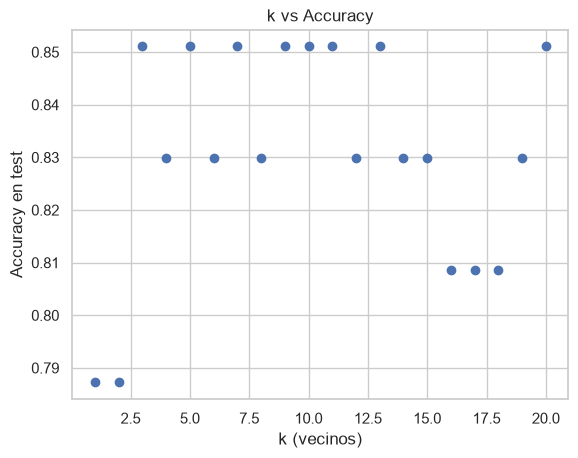

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

ks = list(range(1, 21))
acc_test = []

for k in ks:
  modelo = KNeighborsClassifier(n_neighbors=k)
  modelo.fit(X_train_scaled, y_train)
  pred = modelo.predict(X_test_scaled)
  acc_test.append(accuracy_score(y_test, pred))

# Mejor k (el que tiene mayor accuracy en test)
mejor_k = ks[acc_test.index(max(acc_test))]
print(f"Mejor k: {mejor_k} | Accuracy test: {max(acc_test):.4f}")

# Scatterplot: k vs accuracy
plt.scatter(ks, acc_test)
plt.xlabel("k (vecinos)")
plt.ylabel("Accuracy en test")
plt.title("k vs Accuracy")
plt.show()

## Predice con nuevos datos.
Ejemplo: supongamos que nos llega una review de 5 palabras y sentimiento 1

In [21]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

# 1. Entrenar el modelo con la k elegida (por ejemplo, k = 5 o k = 9)
knn_final = KNeighborsClassifier(n_neighbors=5)
knn_final.fit(X_train_scaled, y_train)

# 2. Nueva reseña: 5 palabras (wordcount=5) y sentimiento 1 (sentimentValue=1)
nueva_review = pd.DataFrame({"wordcount": [5], "sentimentValue": [1]})

# 3. Escalar usando el mismo scaler ajustado en train
nueva_review_scaled = scaler.transform(nueva_review)

# 4. Predecir el Star Rating
prediccion = knn_final.predict(nueva_review_scaled)
print("Star Rating predicho:", prediccion[0])

# Opcional: ver la probabilidad estimada para cada clase
if hasattr(knn_final, "predict_proba"):
  print("Probabilidades por clase:", dict(zip(knn_final.classes_, knn_final.predict_proba(nueva_review_scaled)[0].round(3))))

Star Rating predicho: 5
Probabilidades por clase: {np.int64(1): np.float64(0.0), np.int64(2): np.float64(0.0), np.int64(3): np.float64(0.0), np.int64(4): np.float64(0.0), np.int64(5): np.float64(1.0)}


In [22]:

# Nueva reseña: 85 palabras y sentimiento negativo (-0.8)
review_negativa = pd.DataFrame(
    {"wordcount": [85], "sentimentValue": [-0.8]}
)

# Escalar con el mismo scaler de train y predecir con tu modelo entrenado
review_negativa_scaled = scaler.transform(review_negativa)
pred = knn_final.predict(review_negativa_scaled)

print("Star Rating predicho:", pred[0])
if hasattr(knn_final, "predict_proba"):
  print(
      "Probabilidades por clase:",
      dict(
          zip(
              knn_final.classes_,
              knn_final.predict_proba(review_negativa_scaled)[0].round(3),
          )
      ),
  )

Star Rating predicho: 2
Probabilidades por clase: {np.int64(1): np.float64(0.0), np.int64(2): np.float64(1.0), np.int64(3): np.float64(0.0), np.int64(4): np.float64(0.0), np.int64(5): np.float64(0.0)}
